# Individual renovation measures

Apply every supported renovation operation and inspect its validated physical changes.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

The renovation API separates a **measure description** from applying it. `AddInsulation`, `ReplaceGlazing`, `ChangeAirflow`, `InstallFVP` and `InstallPV` describe the requested operation; `apply_renovation(building, measure, effective_date=...)` returns a new validated `BuildingSpec` with a dated audit record.

The original building is retained for a matched baseline. The physical-quantity branch in the pipeline figure explains why these operations can record material and equipment changes even when the exterior preview looks unchanged. A new physical hash means changed inputs, not demonstrated energy savings.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Construct explicit measures

Insulation specifies element and layer; glazing and airflow replace their complete specifications. FVP requires compatible airflow. PV adds a generation system.

### Read the code and output

Insulation targets a named envelope element and supplies a layer. Glazing and airflow replacements provide complete new specifications, so check every field you intend to retain. An FVP installation also requires compatible airflow; the example deliberately uses a compatible source for that measure rather than quietly modifying the baseline system.

Reference: [Resolved roof shells, openings and attached shading](../../docs/figures/roof-and-facade.svg). This linked documentation illustration is separate from the outputs computed below.

In [2]:
b=building()
layer=b.envelope.wall.layers[0].updated(thickness_m=.1)
measures=[AddInsulation(element="wall",layer=layer),ReplaceGlazing(glazing=GlazingSpec(u_value_w_m2k=1.1,solar_heat_gain_coefficient=.5)),ChangeAirflow(airflow=AirflowSpec(topology="F",envelope_infiltration_ach=.15,mechanical_vent_l_s_m2=.35)),InstallFVP(fvp=FVPSpec(cop=3,capacity_kw=8)),InstallPV(pv=PVSpec(dc_capacity_kw=5))]
table([m.model_dump() for m in measures])

,kind,element,layer,position,glazing,airflow,fvp,pv
0,add_insulation,wall,{'material': {'name': 'demonstration insulatio...,0.0,NaN,NaN,NaN,NaN
1,replace_glazing,NaN,NaN,NaN,"{'u_value_w_m2k': 1.1, 'solar_heat_gain_coeffi...",NaN,NaN,NaN
2,change_airflow,NaN,NaN,NaN,NaN,"{'topology': 'F', 'envelope_infiltration_ach':...",NaN,NaN
3,install_fvp,NaN,NaN,NaN,NaN,NaN,"{'cop': 3.0, 'capacity_kw': 8.0, 'exhaust_min_...",NaN
4,install_pv,NaN,NaN,NaN,NaN,NaN,NaN,"{'dc_capacity_kw': 5.0, 'tilt_deg': 30, 'azimu..."


,kind,element,layer,position,glazing,airflow,fvp,pv
0,add_insulation,wall,{'material': {'name': 'demonstration insulatio...,0.0,NaN,NaN,NaN,NaN
1,replace_glazing,NaN,NaN,NaN,"{'u_value_w_m2k': 1.1, 'solar_heat_gain_coeffi...",NaN,NaN,NaN
2,change_airflow,NaN,NaN,NaN,NaN,"{'topology': 'F', 'envelope_infiltration_ach':...",NaN,NaN
3,install_fvp,NaN,NaN,NaN,NaN,NaN,"{'cop': 3.0, 'capacity_kw': 8.0, 'exhaust_min_...",NaN
4,install_pv,NaN,NaN,NaN,NaN,NaN,NaN,"{'dc_capacity_kw': 5.0, 'tilt_deg': 30, 'azimu..."


## Apply immutable transformations

Use a compatible exhaust-only baseline for the FVP demonstration. Each operation returns a new BuildingSpec and appends an audit record.

### Read the code and output

Each variant starts from its stated source and receives one new renovation record. The FVP variant has a different compatible source from the other variants, so these objects are not yet a matched energy-savings comparison. The original record count assertion protects the baseline from accidental mutation.

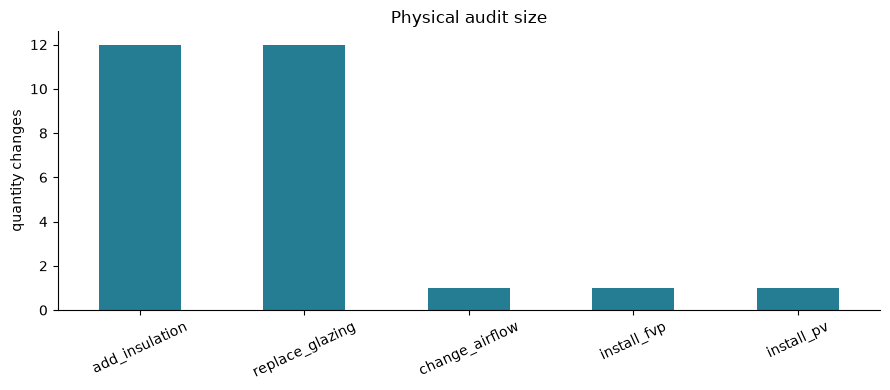

In [3]:
variants={}
for measure in measures:
    source=b.updated(airflow=AirflowSpec(topology="F",envelope_infiltration_ach=.2,mechanical_vent_l_s_m2=.35)) if isinstance(measure,InstallFVP) else b
    changed=apply_renovation(source,measure,effective_date="2026-01-01")
    assert changed.physical_hash()!=source.physical_hash()
    assert len(changed.renovations)==len(source.renovations)+1
    variants[measure.kind]=changed
assert len(b.renovations)==0
bars({name:len(v.renovations[-1].changes) for name,v in variants.items()},"quantity changes","Physical audit size")

## Preview quantities before simulation

A physical retrofit need not alter the visible shell: insulation changes material layers, while PV is represented as a generation system rather than automatically placed roof panels.

### Read the code and output

The quantity-change count is an audit size, not a performance score. Wall U-value can change without a visible change in the resolved shell, and PV is an explicit generation system rather than automatically drawn panels. Run matched simulations before attributing an energy effect to these operations.

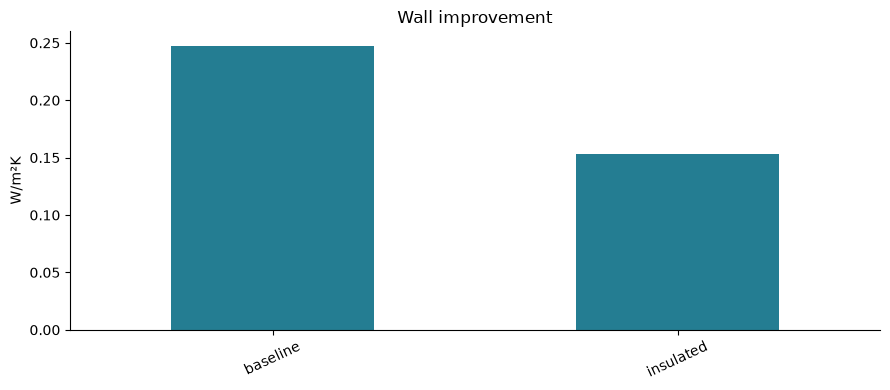

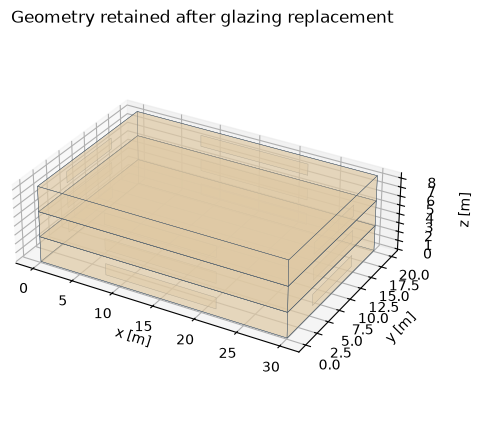

In [4]:
bars({"baseline":b.envelope.wall.u_value_w_m2k,"insulated":variants["add_insulation"].envelope.wall.u_value_w_m2k},"W/m²K","Wall improvement")
preview(variants["replace_glazing"],"Geometry retained after glazing replacement")

## Interpretation and next experiment

Audit each operation before combining it with another. The physical hashes describe changed inputs, not a guarantee of energy savings.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.